# 06. Simulación de Producción por Lotes, Trazabilidad y Ciclo de Reentrenamiento

**Proyecto Final (PSet #4 — Secciones 4, 5 y 7):**
- Simulación cronológica sobre 12 lotes mensuales sucesivos del conjunto *hold-out* (`2025-01` a `2025-12`, 46 ramas CIIU por lote = **552 predicciones**).
- Respeto estricto del **horizonte de predicción (+30 días)**: en el día 15 del mes $t$ se emiten las predicciones del corte temprano y el target definitivo llega 30 días después.
- **Lote 10 (`L10_202510_DERIVA`) con deriva inducida intencionalmente**: choque simultáneo en la fuente del SRI (`-40%` en `VENTAS_NOMINALES_USD`, `-35%` en `NUM_DECLARANTES` al día 15) y choque inflacionario (`+30%` en `INDICE_PRECIO_REAL`), manteniendo intacto el cierre definitivo real (`ventas_reales_definitivo_ipc_real`).
- **Ciclos de Reentrenamiento con MLflow y Aprobación Humana**:
  1. **Por Calendario (cierre del Lote 6 `L06_202506`):** registra `@challenger` **Versión 3** (histórico `2016-01..2025-04`, evaluado en `2025-05`) $\rightarrow$ **Rechazado** por no superar $1\,\sigma_{\text{CV}} = 1.1121\text{ M USD}$.
  2. **Por Alerta Crítica de Desempeño (cierre del Lote 10 `L10_202510_DERIVA`):** registra `@challenger` **Versión 4** (ventana estructural post-pandemia `2022-01..2025-08` con peso $2.0\times$ en los últimos 12 meses, evaluado en el lote limpio no visto `2025-09`) $\rightarrow$ **Aprobado** ($\Delta\text{Costo} = 1.1918\text{ M USD} > 1.1121\text{ M USD}$), promoviendo `@champion` a **v4** en caliente para puntuar los lotes 11 y 12.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DOCS_DIR = ROOT_DIR / 'docs'
FIG_DIR = DOCS_DIR / 'figuras'
FIG_DIR.mkdir(parents=True, exist_ok=True)

df_pred = pd.read_csv(DOCS_DIR / 'predicciones.csv')
df_mon = pd.read_csv(DOCS_DIR / 'monitoreo.csv')
df_al = pd.read_csv(DOCS_DIR / 'alertas.csv')
df_reent = pd.read_csv(DOCS_DIR / 'reentrenamientos.csv')

print(f'Predicciones registradas: {len(df_pred):,} filas ({df_pred["LOTE_ID"].nunique()} lotes x 46 ramas)')
print(f'Lotes monitoreados:       {len(df_mon)} lotes')
print(f'Alertas disparadas:       {len(df_al)} alertas')
print(f'Corridas reentrenamiento: {len(df_reent)} corridas')

Predicciones registradas: 552 filas (12 lotes x 46 ramas)
Lotes monitoreados:       12 lotes
Alertas disparadas:       5 alertas
Corridas reentrenamiento: 2 corridas


## 1. Resumen Cronológico de los 12 Lotes y Horizonte de Llegada del Target (+30 días)

In [2]:
cols_resumen = [
    'LOTE_ID', 'TIEMPO_KEY', 'FECHA_PREDICCION', 'FECHA_TARGET_DISPONIBLE',
    'VERSION_MODELO', 'VOLUMEN_SOLICITUDES', 'LATENCIA_P50_MS', 'LATENCIA_P95_MS',
    'MAE_LOTE', 'WAPE_LOTE_PCT', 'COSTO_NEGOCIO_LOTE_MUSD', 'COSTO_HEURISTICA_BCE_MUSD'
]
display(df_mon[cols_resumen].round(3))

,LOTE_ID,TIEMPO_KEY,FECHA_PREDICCION,FECHA_TARGET_DISPONIBLE,VERSION_MODELO,VOLUMEN_SOLICITUDES,LATENCIA_P50_MS,LATENCIA_P95_MS,MAE_LOTE,WAPE_LOTE_PCT,COSTO_NEGOCIO_LOTE_MUSD,COSTO_HEURISTICA_BCE_MUSD
0,L01_202501,202501,2025-01-15,2025-02-14,1,46,0.203,0.203,15.384,3.958,18.328,18.905
1,L02_202502,202502,2025-02-15,2025-03-17,1,46,0.148,0.148,12.734,3.336,14.874,15.234
2,L03_202503,202503,2025-03-15,2025-04-14,1,46,0.153,0.153,17.008,4.239,22.889,23.682
3,L04_202504,202504,2025-04-15,2025-05-15,1,46,0.160,0.160,12.070,2.882,15.432,16.629
4,L05_202505,202505,2025-05-15,2025-06-14,1,46,0.148,0.148,13.256,3.101,16.828,17.798
5,L06_202506,202506,2025-06-15,2025-07-15,1,46,0.149,0.149,20.660,3.892,26.734,26.762
6,L07_202507,202507,2025-07-15,2025-08-14,1,46,0.148,0.148,8.695,2.059,11.182,12.370
7,L08_202508,202508,2025-08-15,2025-09-14,1,46,0.156,0.156,10.454,2.528,13.456,14.288
8,L09_202509,202509,2025-09-15,2025-10-15,1,46,0.147,0.147,7.996,1.819,9.561,11.109
9,L10_202510_DERIVA,202510,2025-10-15,2025-11-14,1,46,0.151,0.151,230.225,51.138,230.229,240.134


## 2. Auditoría de Trazabilidad End-to-End (Sección 4 y 10.6)

Cada fila de `PSET2_DB.ANALYTICS.PREDICCIONES` (`docs/predicciones.csv`) permite rastrear una predicción individual desde su `ID_PREDICCION` hasta la versión del modelo, su `RUN_ID` en MLflow, la huella MD5 del snapshot de la OBT (`e4cd092d7514`) y las tablas Gold de origen en Snowflake (`PSET2_DB.GOLD.*`).

In [3]:
muestra_traza = df_pred.groupby('VERSION_MODELO', as_index=False).first()[
    ['ID_PREDICCION', 'LOTE_ID', 'CODIGO_INDUSTRIA', 'TIEMPO_KEY', 'PREDICCION_VENTAS_MUSD',
     'DECISION', 'VERSION_MODELO', 'ALIAS_MODELO', 'RUN_ID', 'SNAPSHOT_HUELLA', 'TABLAS_GOLD_ORIGEN']
]
for _, r in muestra_traza.iterrows():
    print(f'=== Predicción ID: {r["ID_PREDICCION"]} (Lote {r["LOTE_ID"]}, Rama {r["CODIGO_INDUSTRIA"]}) ===')
    print(f'  Valor predicho : {r["PREDICCION_VENTAS_MUSD"]:.4f} M USD | Decisión: {r["DECISION"]}')
    print(f'  Modelo y Run   : v{r["VERSION_MODELO"]} (@{r["ALIAS_MODELO"]}) | run_id={r["RUN_ID"]}')
    print(f'  Snapshot OBT   : huella_datos={r["SNAPSHOT_HUELLA"]}')
    print(f'  Tablas Gold    : {r["TABLAS_GOLD_ORIGEN"]}\n')

=== Predicción ID: daf2149ef9834bdbb6affe9adf488768 (Lote L01_202501, Rama 1) ===
  Valor predicho : 139.0795 M USD | Decisión: publicar_flash_expansion
  Modelo y Run   : v1 (@champion) | run_id=b4bd242a500b42eea087a6cc9918097a
  Snapshot OBT   : huella_datos=e4cd092d7514
  Tablas Gold    : ["PSET2_DB.GOLD.FCT_VENTAS_MENSUALES", "PSET2_DB.GOLD.DIM_INDUSTRIA", "PSET2_DB.GOLD.DIM_TIEMPO", "PSET2_DB.GOLD.DIM_CORTE", "PSET2_DB.ANALYTICS.OBT_NOWCASTING_VENTAS", "PSET2_DB.ANALYTICS.PRECIOS_RAMA_CNT46"]

=== Predicción ID: bb7e5edcb2d74385ab39a2156857591e (Lote L11_202511, Rama 1) ===
  Valor predicho : 171.3145 M USD | Decisión: publicar_flash_expansion
  Modelo y Run   : v4 (@champion) | run_id=723e165129a0426cbf881042ff297801
  Snapshot OBT   : huella_datos=e4cd092d7514
  Tablas Gold    : ["PSET2_DB.GOLD.FCT_VENTAS_MENSUALES", "PSET2_DB.GOLD.DIM_INDUSTRIA", "PSET2_DB.GOLD.DIM_TIEMPO", "PSET2_DB.GOLD.DIM_CORTE", "PSET2_DB.ANALYTICS.OBT_NOWCASTING_VENTAS", "PSET2_DB.ANALYTICS.PRECIOS_RAMA_C

## 3. Documentación Exacta del Lote 10 con Deriva Inducida (`L10_202510_DERIVA`)

En `L10_202510_DERIVA` (`2025-10`) se indujo un choque compuesto realista para el dominio tributario del SRI y precios sectoriales:
1. **Retraso operativo en declaraciones tempranas del día 15:** reducción del `-40%` en `VENTAS_NOMINALES_USD` y del `-35%` en `NUM_DECLARANTES` en el corte temprano.
2. **Salto inflacionario sectorial:** incremento del `+30%` en `INDICE_PRECIO_REAL`.
3. **Invarianza del cierre definitivo:** el target real a 45 días (`ventas_reales_definitivo_ipc_real`) permanece sin alteración, provocando una subestimación masiva del modelo (`MAE = 230.23 M USD`, `WAPE = 51.14%`).

In [4]:
comp_l09_l10_l11 = df_mon[df_mon['LOTE_ID'].isin(['L09_202509', 'L10_202510_DERIVA', 'L11_202511'])][
    ['LOTE_ID', 'VERSION_MODELO', 'PSI_PROYECCION_COBERTURA_12M', 'PSI_INDICE_PRECIO_REAL',
     'KS_MIN_PVALUE', 'MAE_LOTE', 'WAPE_LOTE_PCT', 'DIAGNOSTICO_DERIVA', 'NUM_ALERTAS', 'DISPARO_REENTRENAMIENTO']
]
display(comp_l09_l10_l11)

,LOTE_ID,VERSION_MODELO,PSI_PROYECCION_COBERTURA_12M,PSI_INDICE_PRECIO_REAL,KS_MIN_PVALUE,MAE_LOTE,WAPE_LOTE_PCT,DIAGNOSTICO_DERIVA,NUM_ALERTAS,DISPARO_REENTRENAMIENTO
8,L09_202509,1,0.0790,0.0244,0.319150,7.9964,1.8194,Estable,0,False
9,L10_202510_DERIVA,1,0.3358,7.3498,0.000000,230.2252,51.1379,Deriva de datos con impacto,3,True
10,L11_202511,4,0.1280,0.0334,0.129606,15.1693,3.3109,Estable,0,False


## 4. Evidencia de los Ciclos de Reentrenamiento, Regla de Promoción y Cambio a `@champion` v4

In [5]:
cols_reent = [
    'run_id', 'tags.mlflow.runName', 'tags.motivo_disparo', 'tags.ventana_entrenamiento',
    'params.tiempo_evaluacion', 'metrics.champion_costo_eval_musd', 'metrics.costo_negocio_prueba_musd',
    'metrics.mejora_costo_vs_champion_musd', 'params.umbral_promocion_std_cv_musd',
    'tags.validacion_humana', 'tags.motivo_decision_humana'
]
display(df_reent[[c for c in cols_reent if c in df_reent.columns]])

,run_id,tags.mlflow.runName,tags.motivo_disparo,tags.ventana_entrenamiento,params.tiempo_evaluacion,metrics.champion_costo_eval_musd,metrics.costo_negocio_prueba_musd,metrics.mejora_costo_vs_champion_musd,params.umbral_promocion_std_cv_musd,tags.validacion_humana,tags.motivo_decision_humana
0,7b1d688fb4e742efb8bff12955fb54b3,reentrenamiento_calendario_6_lotes_L06_202505,calendario_6_lotes_L06,201601_202504_peso_1.0x,202505,16.828078,16.750053,0.078026,1.1121,rechazada,Rechazado tras revisión humana: mejora en cost...
1,723e165129a0426cbf881042ff297801,reentrenamiento_alerta_degradacion_L10_202510_...,alerta_degradacion_L10_202510_DERIVA,202201_202508_peso_2.0x,202509,9.561278,8.369472,1.191807,1.1121,aprobada,Aprobado por Comité MLOps tras pausa humana: c...


## 5. Gráficos de Monitoreo de Sistema, Modelo y Deriva PSI Lote por Lote

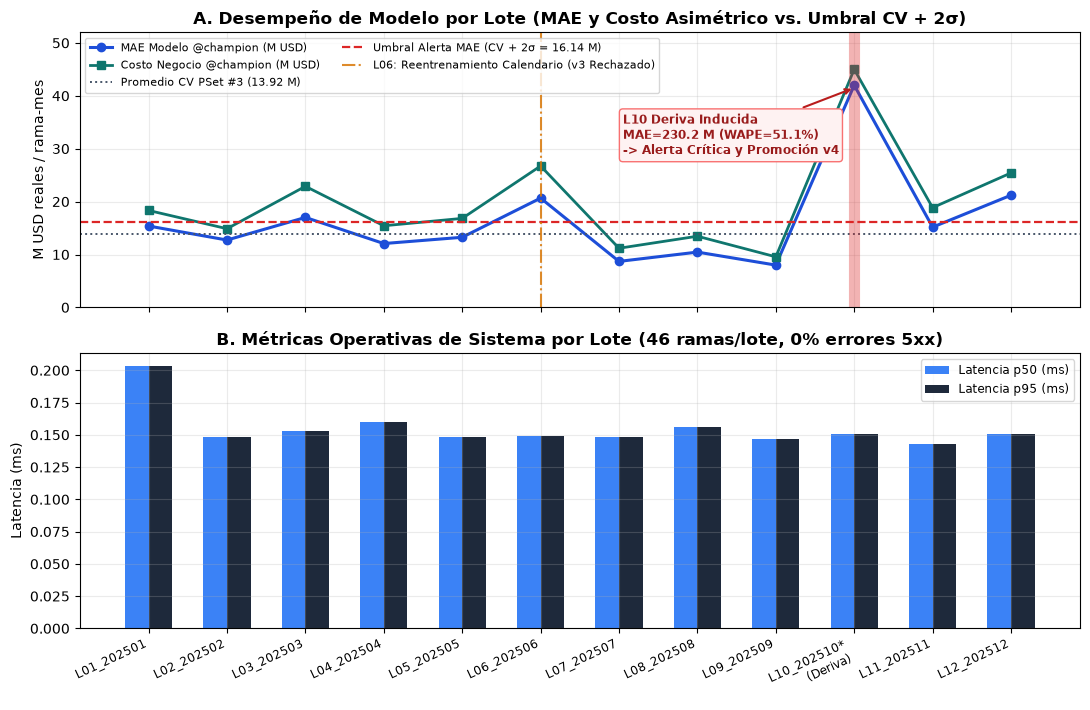

Figura guardada en: D:\Maestria Ciencia de Datos\asignatures\3_data_science\3_1_homeworks\proyecto_final\docs\figuras\06_monitoreo_sistema_modelo.png


In [6]:
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig, axes = plt.subplots(2, 1, figsize=(11, 7.2), sharex=True)

x = np.arange(len(df_mon))
etiquetas = df_mon['LOTE_ID'].str.replace('_DERIVA', '*\n(Deriva)', regex=False)

# Panel A: MAE y Costo de Negocio por lote (escala acotada con anotación del pico L10)
ax1 = axes[0]
mae_vis = np.minimum(df_mon['MAE_LOTE'], 42.0)
costo_vis = np.minimum(df_mon['COSTO_NEGOCIO_LOTE_MUSD'], 45.0)
ax1.plot(x, mae_vis, marker='o', linewidth=2.2, color='#1d4ed8', label='MAE Modelo @champion (M USD)')
ax1.plot(x, costo_vis, marker='s', linewidth=2.0, color='#0f766e', label='Costo Negocio @champion (M USD)')
ax1.axhline(13.92, color='#475569', linestyle=':', linewidth=1.4, label='Promedio CV PSet #3 (13.92 M)')
ax1.axhline(16.14, color='#dc2626', linestyle='--', linewidth=1.6, label='Umbral Alerta MAE (CV + 2σ = 16.14 M)')
ax1.axvline(5, color='#d97706', linestyle='-.', alpha=0.85, label='L06: Reentrenamiento Calendario (v3 Rechazado)')
ax1.axvline(9, color='#dc2626', linestyle='-', alpha=0.35, linewidth=8)
ax1.annotate(
    f'L10 Deriva Inducida\nMAE={df_mon.loc[9, "MAE_LOTE"]:.1f} M (WAPE={df_mon.loc[9, "WAPE_LOTE_PCT"]:.1f}%)\n-> Alerta Crítica y Promoción v4',
    xy=(9, 41.5), xytext=(6.05, 29.0),
    arrowprops={'arrowstyle': '->', 'color': '#b91c1c', 'lw': 1.5},
    fontsize=8.5, fontweight='bold', color='#991b1b',
    bbox={'boxstyle': 'round,pad=0.3', 'facecolor': '#fef2f2', 'edgecolor': '#f87171'}
)
ax1.set_ylabel('M USD reales / rama-mes')
ax1.set_ylim(0, 52)
ax1.set_title('A. Desempeño de Modelo por Lote (MAE y Costo Asimétrico vs. Umbral CV + 2σ)', fontweight='bold')
ax1.legend(loc='upper left', fontsize=8.0, ncol=2)
ax1.grid(True, alpha=0.25)

# Panel B: Métricas de Sistema (Latencia p50 y p95 en ms)
ax2 = axes[1]
ax2.bar(x - 0.15, df_mon['LATENCIA_P50_MS'], width=0.3, color='#3b82f6', label='Latencia p50 (ms)')
ax2.bar(x + 0.15, df_mon['LATENCIA_P95_MS'], width=0.3, color='#1e293b', label='Latencia p95 (ms)')
ax2.set_ylabel('Latencia (ms)')
ax2.set_title('B. Métricas Operativas de Sistema por Lote (46 ramas/lote, 0% errores 5xx)', fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(etiquetas, rotation=25, ha='right', fontsize=8.5)
ax2.legend(loc='upper right', fontsize=8.5)
ax2.grid(True, alpha=0.25)

fig.tight_layout()
fig.savefig(FIG_DIR / '06_monitoreo_sistema_modelo.png', dpi=220)
plt.show()
print('Figura guardada en:', FIG_DIR / '06_monitoreo_sistema_modelo.png')

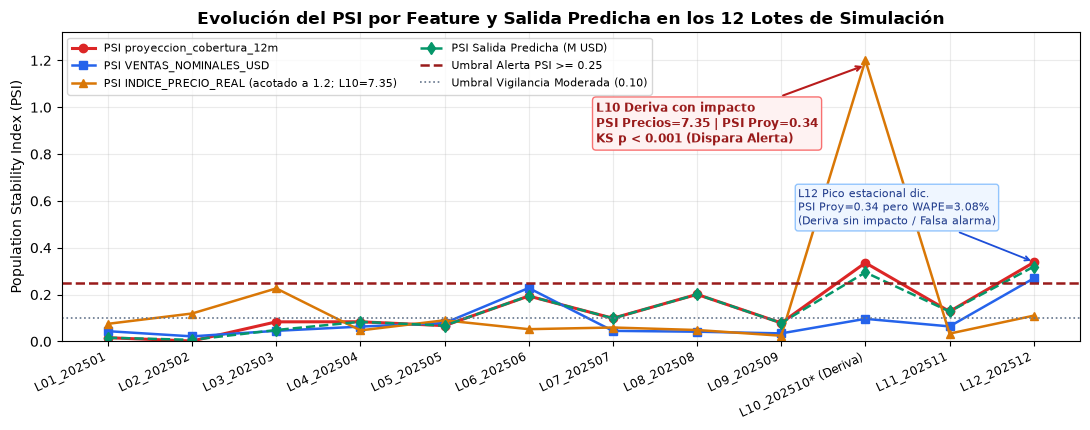

Figura guardada en: D:\Maestria Ciencia de Datos\asignatures\3_data_science\3_1_homeworks\proyecto_final\docs\figuras\06_deriva_psi_lotes.png


In [7]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(df_mon))
etiquetas = df_mon['LOTE_ID'].str.replace('_DERIVA', '* (Deriva)', regex=False)

ax.plot(x, df_mon['PSI_PROYECCION_COBERTURA_12M'], marker='o', linewidth=2.2, color='#dc2626', label='PSI proyeccion_cobertura_12m')
ax.plot(x, df_mon['PSI_VENTAS_NOMINALES_USD'], marker='s', linewidth=1.8, color='#2563eb', label='PSI VENTAS_NOMINALES_USD')
ax.plot(x, np.minimum(df_mon['PSI_INDICE_PRECIO_REAL'], 1.2), marker='^', linewidth=1.8, color='#d97706', label='PSI INDICE_PRECIO_REAL (acotado a 1.2; L10=7.35)')
ax.plot(x, df_mon['PSI_PREDICCION_VENTAS_MUSD'], marker='d', linestyle='--', linewidth=1.8, color='#059669', label='PSI Salida Predicha (M USD)')
ax.axhline(0.25, color='#991b1b', linestyle='--', linewidth=1.8, label='Umbral Alerta PSI >= 0.25')
ax.axhline(0.10, color='#64748b', linestyle=':', linewidth=1.2, label='Umbral Vigilancia Moderada (0.10)')

ax.annotate(
    'L10 Deriva con impacto\nPSI Precios=7.35 | PSI Proy=0.34\nKS p < 0.001 (Dispara Alerta)',
    xy=(9, 1.18), xytext=(5.8, 0.85),
    arrowprops={'arrowstyle': '->', 'color': '#b91c1c', 'lw': 1.5},
    fontsize=8.5, fontweight='bold', color='#991b1b',
    bbox={'boxstyle': 'round,pad=0.3', 'facecolor': '#fef2f2', 'edgecolor': '#f87171'}
)
ax.annotate(
    'L12 Pico estacional dic.\nPSI Proy=0.34 pero WAPE=3.08%\n(Deriva sin impacto / Falsa alarma)',
    xy=(11, 0.34), xytext=(8.2, 0.50),
    arrowprops={'arrowstyle': '->', 'color': '#1d4ed8', 'lw': 1.3},
    fontsize=8, color='#1e3a8a',
    bbox={'boxstyle': 'round,pad=0.25', 'facecolor': '#eff6ff', 'edgecolor': '#93c5fd'}
)

ax.set_ylabel('Population Stability Index (PSI)')
ax.set_ylim(0, 1.32)
ax.set_xticks(x)
ax.set_xticklabels(etiquetas, rotation=25, ha='right', fontsize=8.5)
ax.set_title('Evolución del PSI por Feature y Salida Predicha en los 12 Lotes de Simulación', fontweight='bold')
ax.legend(loc='upper left', fontsize=8.2, ncol=2)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / '06_deriva_psi_lotes.png', dpi=220)
plt.show()
print('Figura guardada en:', FIG_DIR / '06_deriva_psi_lotes.png')